---
title: "Priors"
author: "Erik"
date: "2026-11-22"
---

In [1]:
import framework as fw

fw.scaffold()
import priors  # functions/priors.py, on the path after scaffold()

Random seed set to 123.


Added functions to the import path


## Model

$$
\begin{aligned}
\text{Adult SES}_i &\sim \text{Normal}(\mu_i, \sigma) \\
\mu_i &= \alpha + \beta\,\text{Family SES}_i
\end{aligned}
$$

- Family: Normal.
- Linear model: intercept $\alpha$, slope $\beta$.
- Parameters needing priors: $\alpha$, $\beta$, $\sigma$.

## Standardized variables

In [2]:
mobility = priors.read_mobility()
print(f"n = {len(mobility):,} students with both SES measures")
priors.mean_sd_table(mobility, "w1_ses", "w4_ses", "parent_ses_z", "adult_ses_z")

n = 12,529 students with both SES measures


,mean,sd
w1_ses,0.08,0.75
w4_ses,0.07,0.75
parent_ses_z,0.00,1.00
adult_ses_z,0.00,1.00


- `parent_ses_z` (family SES, 2002) and `adult_ses_z` (adult SES, 2012): mean 0, SD 1.

## Intercept

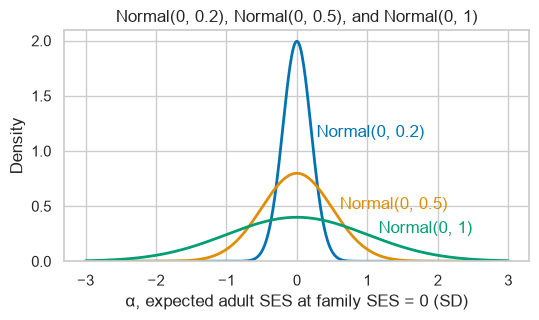

Normal(0, 0.2), 95%: -0.39 to 0.39
Normal(0, 0.5), 95%: -0.98 to 0.98
Normal(0, 1), 95%: -1.96 to 1.96


In [3]:
intercept_priors = [priors.normal(0, 0.2), priors.normal(0, 0.5), priors.normal(0, 1)]

priors.plot_priors(intercept_priors, xlabel="α, expected adult SES at family SES = 0 (SD)", limits=(-3, 3))
for prior in intercept_priors:
    print(f"{prior.name}, 95%: {priors.interval_text(prior)}")

## Slope

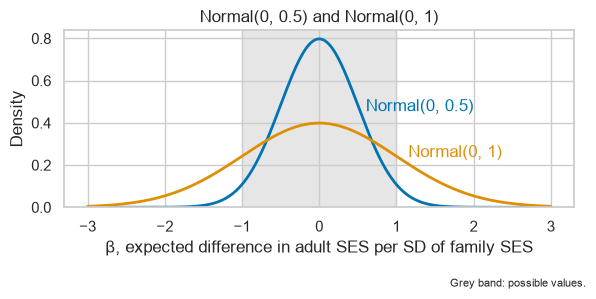

Normal(0, 0.5), 95%: -0.98 to 0.98; share between -1 and 1: 0.95
Normal(0, 1), 95%: -1.96 to 1.96; share between -1 and 1: 0.68


In [4]:
slope_priors = [priors.normal(0, 0.5), priors.normal(0, 1)]

priors.plot_priors(
    slope_priors,
    xlabel="β, expected difference in adult SES per SD of family SES",
    limits=(-3, 3), possible=(-1, 1),
)
for prior in slope_priors:
    print(f"{prior.name}, 95%: {priors.interval_text(prior)}; share between -1 and 1: {priors.share(prior, -1, 1):.2f}")

- Possible values: −1 to 1. With both variables standardized, the slope is the correlation.

## Residual SD

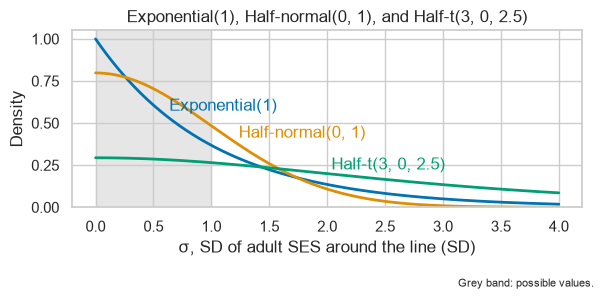

Exponential(1), 95%: 0.03 to 3.69; share above 1: 0.37
Half-normal(0, 1), 95%: 0.03 to 2.24; share above 1: 0.32
Half-t(3, 0, 2.5), 95%: 0.09 to 10.44; share above 1: 0.72


In [5]:
sigma_priors = [priors.exponential(1), priors.half_normal(1), priors.half_t(3, 2.5)]

priors.plot_priors(
    sigma_priors,
    xlabel="σ, SD of adult SES around the line (SD)",
    limits=(0, 4), possible=(0, 1),
)
for prior in sigma_priors:
    print(f"{prior.name}, 95%: {priors.interval_text(prior)}; share above 1: {priors.share(prior, 1):.2f}")

- Possible values: greater than 0 and at most 1, the SD of adult SES.
- Exponential(1): mean 1.
- Half-normal(0, 1): Stan prior recommendations.
- Half-t(3, 0, 2.5): brms default, `student_t(3, 0, 2.5)` with a lower bound of 0.

## Prior predictive simulation

### Prior sets

In [6]:
prior_sets = {
    "Weaker": priors.prior_set(alpha=priors.normal(0, 1), beta=priors.normal(0, 1), sigma=priors.half_t(3, 2.5)),
    "Stronger": priors.prior_set(alpha=priors.normal(0, 0.2), beta=priors.normal(0, 0.5), sigma=priors.exponential(1)),
}
mu = "alpha + beta * parent_ses_z"

priors.prior_set_table(prior_sets)

,set,alpha,beta,sigma
0,Weaker,"Normal(0, 1)","Normal(0, 1)","Half-t(3, 0, 2.5)"
1,Stronger,"Normal(0, 0.2)","Normal(0, 0.5)",Exponential(1)


- Weaker: the widest candidate for each parameter above; its residual SD prior is the brms default.

### Implied lines

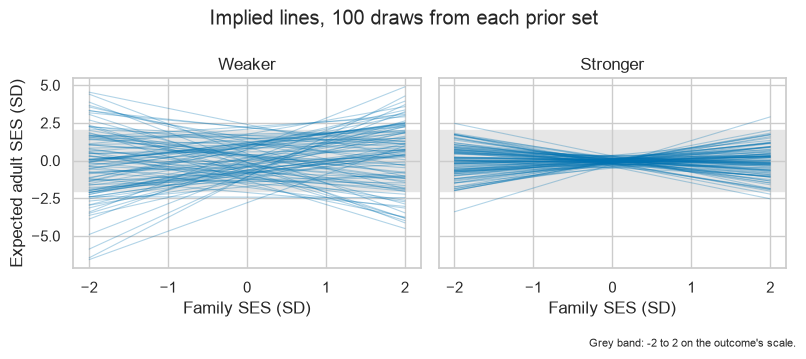

In [7]:
draws = priors.draw_priors(prior_sets, n=4000)

priors.plot_prior_lines(draws, mu, xlabel="Family SES (SD)", ylabel="Expected adult SES (SD)")

### Simulated data

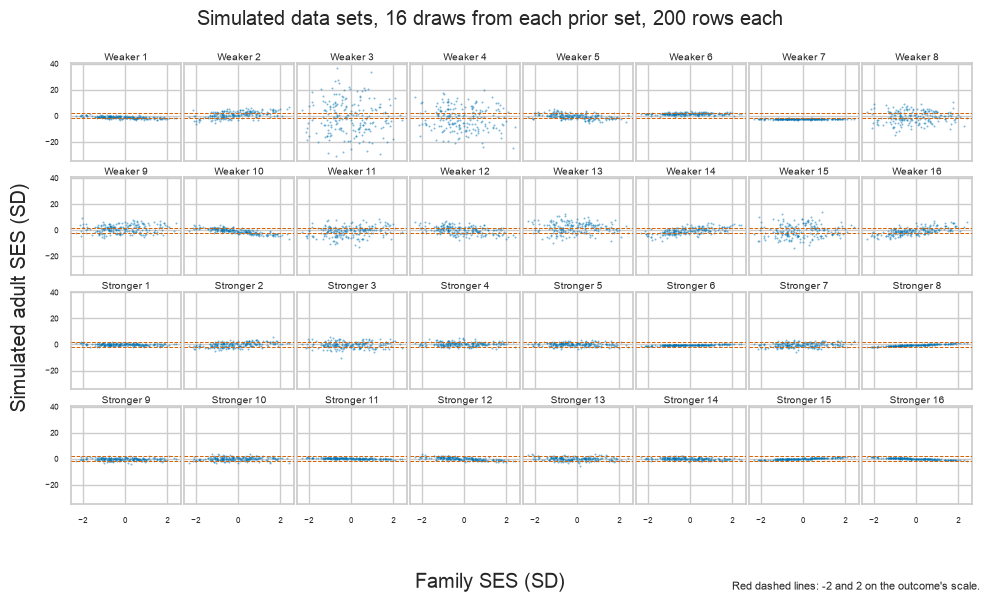

In [8]:
students = mobility[["parent_ses_z"]].sample(200)
simulated = priors.simulate_outcomes(draws, students, mu)

priors.plot_simulated(simulated, "parent_ses_z", xlabel="Family SES (SD)", ylabel="Simulated adult SES (SD)")

- Family SES: real values for 200 students. Adult SES: simulated.

### Implied outcome SD

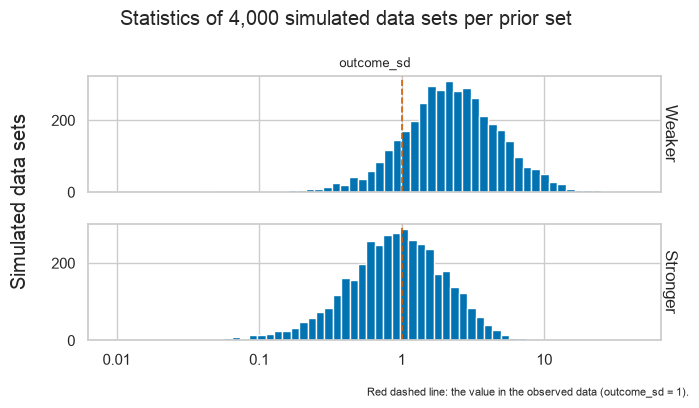

In [9]:
stats = priors.simulated_stats(simulated, outcome_sd=lambda d: d["y"].std())
priors.plot_simulated_stats(stats, reference={"outcome_sd": 1}, log_x=True)

In [10]:
(
    stats.groupby("set", observed=True)["outcome_sd"]
    .agg(median="median", share_above_2=lambda v: (v > 2).mean())
    .round(2)
)

,median,share_above_2
set,,
Weaker,2.21,0.55
Stronger,0.93,0.16


- Outcome SD: the SD of simulated adult SES in each simulated data set.
- Observed: adult SES is standardized with the sample's SD, so any data set on this scale has an SD near 1.